<a href="https://colab.research.google.com/github/herawati12/Projek_Semester5_Poptato/blob/hera/Perbandingan_4_Arsitektur_CNN_Kentang_1000_Drive_Checkpoint_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Perbandingan 4 Arsitektur CNN — Kentang Good vs Bad
**MobileNetV2 | EfficientNetB0 | ResNet50 | VGG16** · Dataset `dataset_papas_hibrido.zip` (Zenodo) · **1.000 gambar** · Google Colab

Notebook eksperimen PBL: semua model menggunakan **gambar yang identik** (700 train, 150 validation, 150 test; kelas seimbang). Model disimpan ke Google Drive, ada **resume checkpoint setiap epoch**, dan hasil akhir berupa tabel perbandingan, confusion matrix, grafik, serta file CSV.

> **Catatan metodologi:** ini studi komparatif terbatas pada 1.000 gambar, **bukan** pengganti evaluasi MobileNetV2 pada seluruh dataset atau bukti performa pada kentang Indonesia. Hash SHA-256 mencegah duplikasi *identik* antar split, tetapi tidak menjamin bebas foto hampir identik atau satu umbi difoto beberapa kali.

**Jalankan sel berurutan.** Aktifkan GPU melalui `Runtime → Change runtime type → T4 GPU`. Simpan ZIP di `MyDrive/PBL_Kentang/dataset_papas_hibrido.zip` atau ubah path pada sel konfigurasi.

## 1 · Setup dan mount Drive

In [6]:
# Paket biasanya sudah tersedia di Google Colab.
# Jika perlu, aktifkan baris berikut satu kali:
# %pip -q install tensorflow scikit-learn pandas matplotlib seaborn pillow

import os, io, json, random, time, shutil, hashlib, zipfile, gc, warnings
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

try:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
except ImportError:
    print('Bukan Colab: gunakan path lokal pada konfigurasi.')

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2 · Konfigurasi eksperimen

In [7]:
# UBAH BAGIAN INI JIKA NAMA FOLDER DRIVE BERBEDA
PROJECT_DIR = Path('/content/drive/MyDrive/PBL_Kentang')
ZIP_PATH = PROJECT_DIR / 'dataset_papas_hibrido.zip'
RESULT_DIR = PROJECT_DIR / 'perbandingan_4cnn_1000'
LOCAL_ROOT = Path('/content/potato_compare_1000')

SEED = 42
BATCH_SIZE = 16
IMG_SIZE = (224, 224)
MAX_EPOCHS = 20
PATIENCE = 5
LEARNING_RATE = 1e-4
REPEATS = 1  # ubah ke 3 SEBELUM memulai eksperimen untuk 3 pengulangan
MODELS = ['MobileNetV2', 'EfficientNetB0', 'ResNet50', 'VGG16']
SPLIT_COUNTS = {'train': 350, 'val': 75, 'test': 75}  # PER KELAS
CLASS_TO_ID = {'Buen estado': 0, 'Defectuoso': 1}
ID_TO_EN = {0: 'Good', 1: 'Bad'}

assert ZIP_PATH.is_file(), f'ZIP tidak ditemukan: {ZIP_PATH}'
RESULT_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print('ZIP:', ZIP_PATH)
print('Hasil:', RESULT_DIR)
print('Total gambar:', sum(SPLIT_COUNTS.values()) * len(CLASS_TO_ID))

ZIP: /content/drive/MyDrive/PBL_Kentang/dataset_papas_hibrido.zip
Hasil: /content/drive/MyDrive/PBL_Kentang/perbandingan_4cnn_1000
Total gambar: 1000


## 3 · Audit hash dan buat **manifest 1.000 gambar**
- Mengambil gambar sesuai subset **asli** (`train`, `val`, `test`) untuk mengurangi risiko kebocoran.
- Menghitung SHA-256 seluruh file citra dalam ZIP; mengeluarkan hash yang muncul pada lebih dari satu subset asli.
- Menyimpan pilihan file ke `manifest_1000.csv` di Drive, sehingga saat koneksi terputus **gambar yang sama tetap dipakai**.
- Jika manifest sudah ada, pemilihan **tidak diulang**. Jangan mengganti seed/setting setelah training dimulai.

In [8]:
MANIFEST_PATH = RESULT_DIR / 'manifest_1000.csv'
META_PATH = RESULT_DIR / 'experiment_config.json'
config = dict(seed=SEED, batch_size=BATCH_SIZE, image_size=list(IMG_SIZE),
              max_epochs=MAX_EPOCHS, learning_rate=LEARNING_RATE, repeats=REPEATS,
              models=MODELS, split_counts=SPLIT_COUNTS, class_to_id=CLASS_TO_ID,
              zip_filename=ZIP_PATH.name)
if META_PATH.exists():
    previous = json.loads(META_PATH.read_text())
    assert previous == config, ('Konfigurasi berubah dari eksperimen sebelumnya. '
                                'Gunakan folder RESULT_DIR baru untuk eksperimen lain.')
else:
    META_PATH.write_text(json.dumps(config, indent=2, ensure_ascii=False))

if MANIFEST_PATH.exists():
    manifest = pd.read_csv(MANIFEST_PATH)
    print('Memakai manifest tersimpan:', MANIFEST_PATH)
else:
    records, hash_to_splits = [], defaultdict(set)
    with zipfile.ZipFile(ZIP_PATH) as z:
        filenames = [i.filename for i in z.infolist()
                     if not i.is_dir() and i.filename.lower().endswith(('.jpg', '.jpeg', '.png'))]
        print('Menghitung hash', len(filenames), 'gambar; tahap ini bisa cukup lama...')
        for name in filenames:
            parts = name.split('/')
            if len(parts) < 3 or parts[0] not in SPLIT_COUNTS or parts[1] not in CLASS_TO_ID:
                continue
            sha = hashlib.sha256(z.read(name)).hexdigest()
            records.append((parts[0], parts[1], name, sha))
            hash_to_splits[sha].add(parts[0])
    df_all = pd.DataFrame(records, columns=['split', 'class_name', 'zip_member', 'sha256'])
    cross_hashes = {h for h, subsets in hash_to_splits.items() if len(subsets) > 1}
    print('Hash identik yang melintasi split:', len(cross_hashes))
    clean = df_all[~df_all['sha256'].isin(cross_hashes)].copy()
    # Buang juga duplikat identik di dalam subset; satu hash hanya satu kali
    clean = clean.drop_duplicates('sha256')
    chunks = []
    for split, per_class in SPLIT_COUNTS.items():
        for name in CLASS_TO_ID:
            candidates = clean[(clean.split == split) & (clean.class_name == name)]
            assert len(candidates) >= per_class, f'Tidak cukup gambar: {split}/{name}'
            selected = candidates.sample(n=per_class, random_state=SEED).copy()
            selected['label'] = CLASS_TO_ID[name]
            chunks.append(selected)
    manifest = pd.concat(chunks, ignore_index=True)
    manifest.to_csv(MANIFEST_PATH, index=False)
    print('Manifest tersimpan:', MANIFEST_PATH)

assert len(manifest) == 1000
assert manifest.sha256.is_unique, 'Duplikasi identik ditemukan dalam manifest!'
assert (manifest.groupby(['split','label']).size().to_dict() ==
        {(sp, cl): n for sp, n in [('train',350),('val',75),('test',75)] for cl in [0,1]})
print('\nJumlah per split/label:')
print(pd.crosstab(manifest['split'], manifest['label']))
display(manifest.head())

Memakai manifest tersimpan: /content/drive/MyDrive/PBL_Kentang/perbandingan_4cnn_1000/manifest_1000.csv

Jumlah per split/label:
label    0    1
split          
test    75   75
train  350  350
val     75   75


,split,class_name,zip_member,sha256,label
0,train,Buen estado,train/Buen estado/Papa_BE_11520.jpg,126303067bbe564c2e6c77f24458fa6b424ae2c28839e7...,0
1,train,Buen estado,train/Buen estado/Papa_BE_6924.jpg,1335d84d7b39ab6bd70c978889a5a732ce1e470dda3743...,0
2,train,Buen estado,train/Buen estado/Papa_BE_14633.jpg,4ac76770ecb4b2b25eebcd1f0ce84279e1d884f3b1f964...,0
3,train,Buen estado,train/Buen estado/Papa_BE_4934.jpg,6b302eb69d0fbd44a0fe2c7fe465f1393b08be28010302...,0
4,train,Buen estado,train/Buen estado/Papa_BE_9344.jpg,6d8ce70357dade1295e44b96b6ad0839982fe04afbb03f...,0


## 4 · Ekstrak hanya 1.000 gambar ke penyimpanan Colab

In [9]:
# Data diekstrak ke /content untuk I/O training cepat; hasil/checkpoint tetap di Drive.
# Jika runtime direset, jalankan kembali sel ini tanpa mengubah manifest.
with zipfile.ZipFile(ZIP_PATH) as z:
    for row in manifest.itertuples(index=False):
        target = LOCAL_ROOT / row.zip_member
        if not target.exists():
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(z.read(row.zip_member))

manifest['local_path'] = manifest['zip_member'].map(lambda s: str(LOCAL_ROOT / s))
assert manifest['local_path'].map(lambda p: Path(p).is_file()).all()
print('1.000 gambar tersedia di:', LOCAL_ROOT)

1.000 gambar tersedia di: /content/potato_compare_1000


## 5 · Dataset dan preprocessing **berbeda untuk tiap arsitektur**

In [10]:
AUTOTUNE = tf.data.AUTOTUNE

def get_preprocessor(name):
    # Input dari tf.data selalu RGB float32 0..255.
    if name == 'MobileNetV2':
        return tf.keras.applications.mobilenet_v2.preprocess_input
    if name == 'EfficientNetB0':
        # Keras EfficientNetB0 menyertakan preprocessing internal, sehingga raw 0..255.
        return tf.keras.applications.efficientnet.preprocess_input
    if name == 'ResNet50':
        return tf.keras.applications.resnet50.preprocess_input
    if name == 'VGG16':
        return tf.keras.applications.vgg16.preprocess_input
    raise ValueError(name)

def build_dataset(split, name, seed=SEED, augment=False):
    part = manifest[manifest['split'] == split]
    paths = part.local_path.tolist()
    labels = part.label.astype('float32').tolist()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if augment:
        ds = ds.shuffle(len(paths), seed=seed, reshuffle_each_iteration=True)
    preprocessor = get_preprocessor(name)

    def load(path, label):
        raw = tf.io.read_file(path)
        image = tf.io.decode_image(raw, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(tf.cast(image, tf.float32), IMG_SIZE)
        if augment:
            image = tf.image.random_flip_left_right(image)
            image = tf.image.random_flip_up_down(image)
        image = preprocessor(image)
        image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
        return image, tf.reshape(label, (1,))

    # Agar shuffle/augmentasi tidak mengubah label relatif terhadap gambar.
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

for architecture in MODELS:
    sample_ds = build_dataset('train', architecture)
    xx, yy = next(iter(sample_ds))
    print(architecture, 'shape:', xx.shape, 'range:',
          (float(tf.reduce_min(xx)), float(tf.reduce_max(xx))), 'label:', yy[:3].numpy().ravel())

MobileNetV2 shape: (16, 224, 224, 3) range: (-1.0, 1.0) label: [0. 0. 0.]
EfficientNetB0 shape: (16, 224, 224, 3) range: (0.0, 255.0) label: [0. 0. 0.]
ResNet50 shape: (16, 224, 224, 3) range: (-103.93900299072266, 151.06100463867188) label: [0. 0. 0.]
VGG16 shape: (16, 224, 224, 3) range: (-103.93900299072266, 151.06100463867188) label: [0. 0. 0.]


## 6 · Bangun empat model dengan head setara

In [11]:
ARCHITECTURES = {
    'MobileNetV2': tf.keras.applications.MobileNetV2,
    'EfficientNetB0': tf.keras.applications.EfficientNetB0,
    'ResNet50': tf.keras.applications.ResNet50,
    'VGG16': tf.keras.applications.VGG16,
}

def create_model(name):
    base = ARCHITECTURES[name](include_top=False, weights='imagenet',
                               input_shape=(*IMG_SIZE, 3))
    base.trainable = False  # protokol perbandingan: backbone frozen untuk SEMUA model
    inp = tf.keras.Input(shape=(*IMG_SIZE, 3), name='input_preprocessed')
    x = base(inp, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D(name='global_pool')(x)
    x = tf.keras.layers.Dropout(0.2, name='dropout')(x)
    out = tf.keras.layers.Dense(1, activation='sigmoid', name='probability_bad')(x)
    result = tf.keras.Model(inp, out, name=f'{name}_good_bad')
    result.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
                   loss='binary_crossentropy',
                   metrics=[tf.keras.metrics.BinaryAccuracy(name='accuracy'),
                            tf.keras.metrics.Precision(name='precision_bad'),
                            tf.keras.metrics.Recall(name='recall_bad')])
    return result

print('Model yang akan diuji:', ', '.join(MODELS))
print('Semua model: ImageNet, frozen backbone, GAP + Dropout(0.2) + sigmoid.')

Model yang akan diuji: MobileNetV2, EfficientNetB0, ResNet50, VGG16
Semua model: ImageNet, frozen backbone, GAP + Dropout(0.2) + sigmoid.


## 7 · Training dengan **checkpoint + resume otomatis**
Checkpoint ditulis **setiap akhir epoch** ke folder Drive per arsitektur dan seed. Jika Colab terputus: mount Drive lagi, jalankan sel setup sampai dataset, lalu **jalankan sel training ini lagi**. `BackupAndRestore` akan memulihkan epoch dan state optimizer yang tersimpan. Epoch yang sedang berjalan ketika putus dapat perlu diulang.

- `best_model.keras`: model terbaik menurut `val_loss`.
- `backup/`: status latihan untuk melanjutkan training.
- `history.csv`: log tiap epoch.
- `metrics.json`: tanda model sudah selesai dievaluasi sehingga dilewati pada rerun.

**Jangan menghapus atau mengubah folder checkpoint ketika ingin resume.** Jika ingin memulai ulang dari nol, gunakan folder hasil berbeda. Jangan jalankan dua runtime sekaligus pada folder checkpoint yang sama.

In [12]:
def get_run_dir(name, repeat):
    return RESULT_DIR / f'{name}_seed{SEED + repeat}'

def train_one(name, repeat=0):
    seed = SEED + repeat
    run_dir = get_run_dir(name, repeat)
    run_dir.mkdir(parents=True, exist_ok=True)
    best_path = run_dir / 'best_model.keras'
    metrics_path = run_dir / 'metrics.json'
    finished_flag = run_dir / 'training_finished.flag'
    if finished_flag.exists() or metrics_path.exists():
        print(f'[SKIP] {name} seed={seed}: training sudah selesai.')
        return

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(seed)
    train_ds = build_dataset('train', name, seed=seed, augment=True)
    val_ds = build_dataset('val', name, seed=seed, augment=False)
    print(f'\n=== Training {name} / seed {seed} ===')
    model = create_model(name)

    # Jangan menimpa best model saat resume jika val_loss sempat lebih buruk.
    log_path = run_dir / 'history.csv'
    best_so_far = None
    if log_path.exists():
        history_old = pd.read_csv(log_path, on_bad_lines='skip')
        if 'val_loss' in history_old.columns:
            values = pd.to_numeric(history_old['val_loss'], errors='coerce').dropna()
            if len(values):
                best_so_far = float(values.min())
    callbacks = [
        tf.keras.callbacks.BackupAndRestore(backup_dir=str(run_dir / 'backup'),
                                            save_freq='epoch', delete_checkpoint=False),
        tf.keras.callbacks.ModelCheckpoint(filepath=str(best_path), monitor='val_loss',
                                           mode='min', save_best_only=True, verbose=1,
                                           initial_value_threshold=best_so_far),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE,
                                         mode='min', restore_best_weights=False),
        tf.keras.callbacks.CSVLogger(str(run_dir / 'history.csv'), append=True),
    ]
    start = time.perf_counter()
    model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
              callbacks=callbacks, verbose=1)
    elapsed = time.perf_counter() - start
    # Timing hanya untuk sesi ini; bisa parsial jika terjadi resume.
    (run_dir / 'last_session_seconds.txt').write_text(str(elapsed))
    finished_flag.write_text('training completed')
    print(f'Selesai {name}; best model: {best_path}')
    del model
    tf.keras.backend.clear_session()
    gc.collect()

for repeat in range(REPEATS):
    for name in MODELS:
        train_one(name, repeat)

print('Training tahap ini selesai. Lanjutkan ke sel evaluasi.')

[SKIP] MobileNetV2 seed=42: training sudah selesai.
[SKIP] EfficientNetB0 seed=42: training sudah selesai.
[SKIP] ResNet50 seed=42: training sudah selesai.
[SKIP] VGG16 seed=42: training sudah selesai.
Training tahap ini selesai. Lanjutkan ke sel evaluasi.


## 8 · Evaluasi test set yang sama: accuracy, precision/recall/F1 Bad, confusion matrix, ukuran dan latensi
`Bad` diberi label **1**, jadi semua metrik `Bad` memakai `pos_label=1`. Prediksi dan laporan diekspor untuk pemeriksaan ulang. Pengukuran latensi memakai **batch 1** dengan 10 warm-up + 50 eksekusi; ini hanyalah perkiraan waktu forward-pass di runtime yang sedang dipakai, bukan hasil pengukuran ESP32.

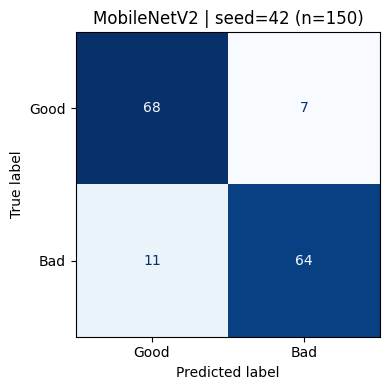

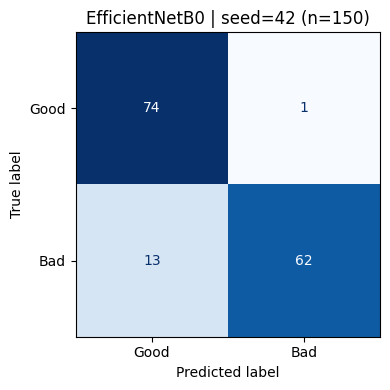

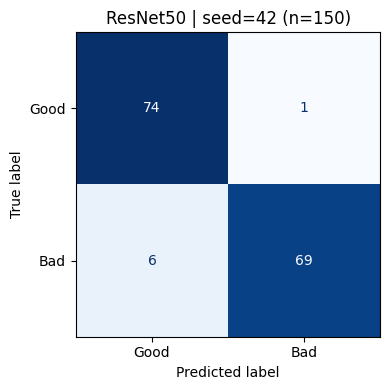

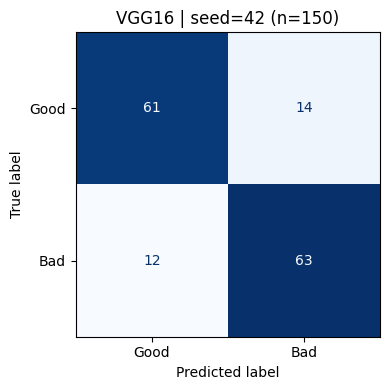

,model,seed,accuracy,precision_bad,recall_bad,f1_bad,file_size_mb,inference_median_ms,true_bad_pred_good
0,MobileNetV2,42,0.8800,0.9014,0.8533,0.8767,9.19,148.5671,11
1,EfficientNetB0,42,0.9067,0.9841,0.8267,0.8986,16.27,301.8936,13
2,ResNet50,42,0.9533,0.9857,0.9200,0.9517,90.63,224.5901,6
3,VGG16,42,0.8267,0.8182,0.8400,0.8289,56.23,24.7621,12


CSV tersimpan: /content/drive/MyDrive/PBL_Kentang/perbandingan_4cnn_1000/perbandingan_hasil.csv


In [13]:
def evaluate_one(name, repeat=0):
    run_dir = get_run_dir(name, repeat)
    best_path = run_dir / 'best_model.keras'
    metrics_path = run_dir / 'metrics.json'
    if metrics_path.exists():
        return json.loads(metrics_path.read_text())
    if not best_path.exists():
        raise FileNotFoundError(f'Model belum ada: {best_path}')
    tf.keras.backend.clear_session()
    gc.collect()
    model = tf.keras.models.load_model(best_path)
    test_ds = build_dataset('test', name, augment=False)
    # test_ds dibuat dari manifest urutan tetap (tidak shuffle)
    y_true = manifest[manifest['split'] == 'test'].label.to_numpy(dtype=int)
    y_prob = model.predict(test_ds, verbose=0).reshape(-1)
    y_pred = (y_prob >= 0.5).astype(int)
    assert len(y_true) == len(y_prob) == 150
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])
    predictions = manifest[manifest['split'] == 'test'][['zip_member', 'label']].copy()
    predictions['prob_bad'] = y_prob
    predictions['prediction'] = y_pred
    predictions.to_csv(run_dir / 'test_predictions.csv', index=False)
    (run_dir / 'classification_report.txt').write_text(classification_report(
        y_true, y_pred, labels=[0,1], target_names=['Good','Bad'], digits=4,
        zero_division=0))
    fig, ax = plt.subplots(figsize=(5,4))
    ConfusionMatrixDisplay(cm, display_labels=['Good','Bad']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name} | seed={SEED+repeat} (n=150)')
    fig.tight_layout()
    fig.savefig(run_dir / 'confusion_matrix.png', dpi=160)
    plt.show()
    plt.close(fig)

    # Waktu inferensi model saja, preprocessing dan decoding tidak dihitung.
    one_x, _ = next(iter(test_ds.unbatch().batch(1)))
    for _ in range(10):
        _ = model(one_x, training=False).numpy()
    latencies = []
    for _ in range(50):
        t0 = time.perf_counter()
        _ = model(one_x, training=False).numpy()
        latencies.append((time.perf_counter() - t0) * 1000)

    row = dict(model=name, seed=SEED + repeat,
               test_samples=len(y_true),
               accuracy=accuracy_score(y_true, y_pred),
               precision_bad=precision_score(y_true, y_pred, zero_division=0),
               recall_bad=recall_score(y_true, y_pred, zero_division=0),
               f1_bad=f1_score(y_true, y_pred, zero_division=0),
               true_good_pred_good=int(cm[0,0]),
               true_good_pred_bad=int(cm[0,1]),
               true_bad_pred_good=int(cm[1,0]),
               true_bad_pred_bad=int(cm[1,1]),
               total_params=int(model.count_params()),
               file_size_mb=round(best_path.stat().st_size / (1024**2), 2),
               inference_median_ms=float(np.median(latencies)),
               inference_mean_ms=float(np.mean(latencies)))
    metrics_path.write_text(json.dumps(row, indent=2))
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return row

rows = []
for repeat in range(REPEATS):
    for name in MODELS:
        rows.append(evaluate_one(name, repeat))

comparison = pd.DataFrame(rows)
comparison.to_csv(RESULT_DIR / 'perbandingan_hasil.csv', index=False)
display(comparison[['model','seed','accuracy','precision_bad','recall_bad','f1_bad',
                    'file_size_mb','inference_median_ms','true_bad_pred_good']].round(4))
print('CSV tersimpan:', RESULT_DIR / 'perbandingan_hasil.csv')

## 9 · Grafik perbandingan empat arsitektur

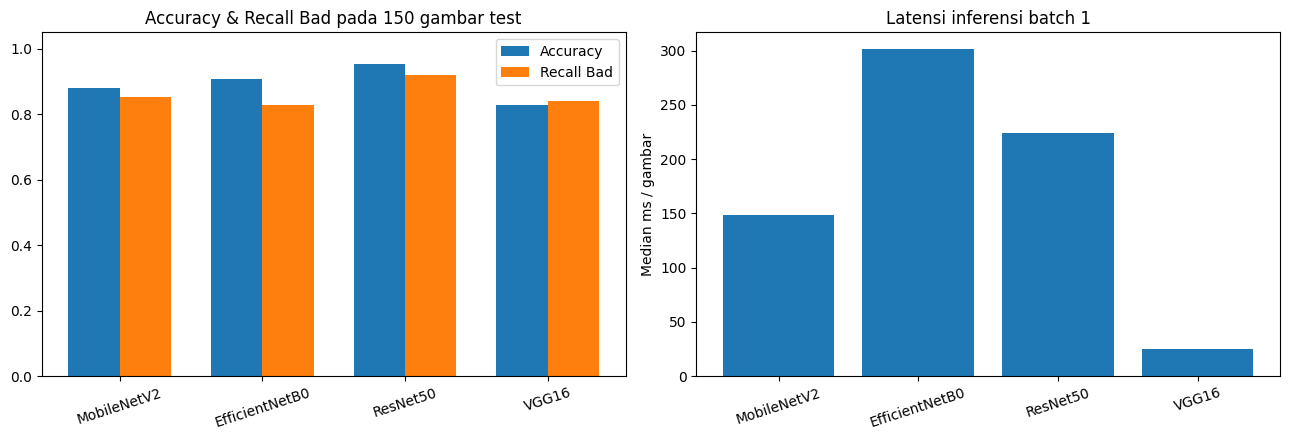

,model,accuracy,precision_bad,recall_bad,f1_bad,file_size_mb,inference_median_ms
0,MobileNetV2,0.8800,0.9014,0.8533,0.8767,9.19,148.5671
1,EfficientNetB0,0.9067,0.9841,0.8267,0.8986,16.27,301.8936
2,ResNet50,0.9533,0.9857,0.9200,0.9517,90.63,224.5901
3,VGG16,0.8267,0.8182,0.8400,0.8289,56.23,24.7621


In [14]:
summary = comparison.groupby('model', as_index=False).agg(
    accuracy=('accuracy', 'mean'), precision_bad=('precision_bad','mean'),
    recall_bad=('recall_bad','mean'), f1_bad=('f1_bad','mean'),
    file_size_mb=('file_size_mb','mean'), inference_median_ms=('inference_median_ms','mean'))
summary = summary.set_index('model').reindex(MODELS).reset_index()
summary.to_csv(RESULT_DIR / 'ringkasan_per_model.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
xx = np.arange(len(MODELS))
axes[0].bar(xx - .18, summary['accuracy'], width=.36, label='Accuracy')
axes[0].bar(xx + .18, summary['recall_bad'], width=.36, label='Recall Bad')
axes[0].set_xticks(xx, MODELS, rotation=18)
axes[0].set_ylim(0, 1.05)
axes[0].set_title('Accuracy & Recall Bad pada 150 gambar test')
axes[0].legend()
axes[1].bar(MODELS, summary['inference_median_ms'])
axes[1].set_ylabel('Median ms / gambar')
axes[1].set_title('Latensi inferensi batch 1')
axes[1].tick_params(axis='x', rotation=18)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'grafik_perbandingan.png', dpi=180)
plt.show()
display(summary.round(4))
if REPEATS > 1:
    print('Rata-rata +/- simpangan baku (accuracy, recall Bad, F1 Bad):')
    display(comparison.groupby('model')[['accuracy','recall_bad','f1_bad']].agg(['mean','std']).round(4))

## 10 · Upload satu foto untuk membandingkan **keempat model**
Foto yang diuji tidak dipakai dalam training atau untuk memilih model. Ini **uji demonstrasi eksternal**, bukan ukuran akurasi model secara keseluruhan. Pemrosesan setiap arsitektur berbeda sesuai Keras. Input gambar dimuat sebagai RGB 0..255 dan *tidak dinormalisasi dua kali*.

Saving freshPotato (6).jpg to freshPotato (6).jpg
File: freshPotato (6).jpg


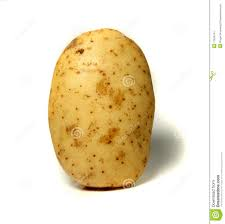

MobileNetV2      : GOOD | P(Bad)=0.1271 | skor kelas terpilih=87.29%
EfficientNetB0   : GOOD | P(Bad)=0.2730 | skor kelas terpilih=72.70%
ResNet50         : GOOD | P(Bad)=0.1300 | skor kelas terpilih=87.00%
VGG16            : BAD  | P(Bad)=0.8918 | skor kelas terpilih=89.18%


In [18]:
from PIL import Image, ImageOps
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    uploaded = {}
    print('Upload otomatis hanya tersedia di Colab.')

for filename, payload in uploaded.items():
    pil = ImageOps.exif_transpose(Image.open(io.BytesIO(payload))).convert('RGB')
    raw = np.array(pil.resize(IMG_SIZE), dtype=np.float32)[None, ...]
    print('File:', filename)
    display(pil.resize((min(450, pil.width), min(450, pil.height))))
    for name in MODELS:
        path = get_run_dir(name, 0) / 'best_model.keras'
        net = tf.keras.models.load_model(path, compile=False)
        x = get_preprocessor(name)(raw.copy())
        p_bad = float(net(x, training=False).numpy()[0,0])
        label = 'BAD' if p_bad >= .5 else 'GOOD'
        print(f'{name:17s}: {label:4s} | P(Bad)={p_bad:.4f} | skor kelas terpilih={max(p_bad,1-p_bad):.2%}')
        del net
        tf.keras.backend.clear_session()
        gc.collect()

## 11 · Batasan & cara melaporkan hasil

1. **Audit duplikasi:** SHA-256 mengidentifikasi gambar identik; perlu audit kemiripan visual dan identitas umbi untuk mencegah kebocoran yang lebih halus.
2. **Konsistensi:** seluruh arsitektur memakai 1.000 file, 3 subset yang sama, head setara dan backbone *frozen*. Preprocessing **sengaja berbeda** sesuai kebutuhan backbone.
3. **Keterbatasan statistik:** test hanya 75 Bad; satu salah prediksi mengubah Recall Bad sebesar 1/75 ≈ 1,33 poin persentase. Untuk klaim yang lebih kuat, lakukan pengulangan beberapa seed dan evaluasi lebih besar.
4. **Checkpoint:** `BackupAndRestore` menyimpan keadaan model/optimizer dan epoch, tetapi hanya pada akhir epoch. Jangan ubah konfigurasi/versi TensorFlow saat resume.
5. **External validity:** validasi pada foto kentang Indonesia memakai kamera alat yang sama sangat diperlukan.
6. **Jangan gabung:** hasil perbandingan 1.000 gambar tidak dapat langsung dibandingkan dengan accuracy MobileNetV2 sebesar 98,36% yang berasal dari pengujian 7.200 gambar pada eksperimen berbeda.
7. **Perangkat:** latensi notebook adalah pada Colab; jangan menuliskannya sebagai latensi pada ESP32.

**Hasil utama untuk slide:** `ringkasan_per_model.csv`, `perbandingan_hasil.csv`, `grafik_perbandingan.png`, dan masing-masing `confusion_matrix.png`.